# COVID-19 Data Analysis — Exploratory Data Analysis (EDA)

**Dataset:** `covid_data.csv`

## Project objectives
- Load and inspect the COVID-19 dataset.
- Check data quality, missing values, and duplicate rows.
- Explore descriptive statistics and country/WHO-region patterns.
- Visualize confirmed cases, deaths, recoveries, active cases, and weekly changes.
- Compare countries and examine relationships between numeric variables.

> This dataset is a country-level snapshot. It should not be interpreted as a current live COVID-19 dashboard.

## 1. Import required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

## 2. Load the dataset
Place `covid_data.csv` in the same folder as this notebook, or update the file path below.

In [2]:
df = pd.read_csv("covid_data.csv")

print("=" * 70)
print("1. DATASET LOADED")
print("=" * 70)
print("Dataset loaded successfully.")

1. DATASET LOADED
Dataset loaded successfully.


## 3. Inspect the dataset

In [3]:
print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape (rows, columns): (187, 15)

Column names:
['Country/Region', 'Confirmed', 'Deaths', 'Recovered', 'Active', 'New cases', 'New deaths', 'New recovered', 'Deaths / 100 Cases', 'Recovered / 100 Cases', 'Deaths / 100 Recovered', 'Confirmed last week', '1 week change', '1 week % increase', 'WHO Region']


In [4]:
print("First five rows:")
display(df.head())

First five rows:


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
0,Afghanistan,36263,1269,25198,9796,106,10,18,3.50,69.49,5.04,35526,737,2.07,Eastern Mediterranean
1,Albania,4880,144,2745,1991,117,6,63,2.95,56.25,5.25,4171,709,17.00,Europe
2,Algeria,27973,1163,18837,7973,616,8,749,4.16,67.34,6.17,23691,4282,18.07,Africa
3,Andorra,907,52,803,52,10,0,0,5.73,88.53,6.48,884,23,2.60,Europe
4,Angola,950,41,242,667,18,1,0,4.32,25.47,16.94,749,201,26.84,Africa


In [5]:
print("Last five rows:")
display(df.tail())

Last five rows:


,Country/Region,Confirmed,Deaths,Recovered,Active,New cases,New deaths,New recovered,Deaths / 100 Cases,Recovered / 100 Cases,Deaths / 100 Recovered,Confirmed last week,1 week change,1 week % increase,WHO Region
182,West Bank and Gaza,10621,78,3752,6791,152,2,0,0.73,35.33,2.08,8916,1705,19.12,Eastern Mediterranean
183,Western Sahara,10,1,8,1,0,0,0,10.00,80.00,12.50,10,0,0.00,Africa
184,Yemen,1691,483,833,375,10,4,36,28.56,49.26,57.98,1619,72,4.45,Eastern Mediterranean
185,Zambia,4552,140,2815,1597,71,1,465,3.08,61.84,4.97,3326,1226,36.86,Africa
186,Zimbabwe,2704,36,542,2126,192,2,24,1.33,20.04,6.64,1713,991,57.85,Africa


In [6]:
print("Dataset information:")
df.info()

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Country/Region          187 non-null    str    
 1   Confirmed               187 non-null    int64  
 2   Deaths                  187 non-null    int64  
 3   Recovered               187 non-null    int64  
 4   Active                  187 non-null    int64  
 5   New cases               187 non-null    int64  
 6   New deaths              187 non-null    int64  
 7   New recovered           187 non-null    int64  
 8   Deaths / 100 Cases      187 non-null    float64
 9   Recovered / 100 Cases   187 non-null    float64
 10  Deaths / 100 Recovered  187 non-null    float64
 11  Confirmed last week     187 non-null    int64  
 12  1 week change           187 non-null    int64  
 13  1 week % increase       187 non-null    float64
 14  WHO Region              187 non-

In [7]:
print("Data types:")
display(df.dtypes.to_frame(name="Data Type"))

Data types:


,Data Type
Country/Region,str
Confirmed,int64
Deaths,int64
Recovered,int64
Active,int64
New cases,int64
New deaths,int64
New recovered,int64
Deaths / 100 Cases,float64
Recovered / 100 Cases,float64


## 4. Data quality checks

In [8]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))
print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:


,Missing Values
Country/Region,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
New cases,0
New deaths,0
New recovered,0
Deaths / 100 Cases,0
Recovered / 100 Cases,0



Total missing values: 0


In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
print("Number of unique countries:", df["Country/Region"].nunique())
print("WHO regions in the dataset:")
print(df["WHO Region"].value_counts())

Number of unique countries: 187
WHO regions in the dataset:
WHO Region
Europe                   56
Africa                   48
Americas                 35
Eastern Mediterranean    22
Western Pacific          16
South-East Asia          10
Name: count, dtype: int64


## 5. Data cleaning
Keep the original dataset intact in `df_raw`, then clean a working copy. This file commonly has no missing values, but these checks make the notebook safer if the CSV changes.

In [11]:
df_raw = df.copy()

# Remove exact duplicate rows, if any
df = df.drop_duplicates().copy()

# Standardize whitespace in text columns
df["Country/Region"] = df["Country/Region"].astype("string").str.strip()
df["WHO Region"] = df["WHO Region"].astype("string").str.strip()

# Convert expected numeric columns to numeric values.
numeric_columns = [
    "Confirmed", "Deaths", "Recovered", "Active", "New cases",
    "New deaths", "New recovered", "Deaths / 100 Cases",
    "Recovered / 100 Cases", "Deaths / 100 Recovered",
    "Confirmed last week", "1 week change", "1 week % increase"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Shape before cleaning:", df_raw.shape)
print("Shape after removing duplicate rows:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame(name="Missing Values"))

Shape before cleaning: (187, 15)
Shape after removing duplicate rows: (187, 15)

Missing values after cleaning:


,Missing Values
Country/Region,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
New cases,0
New deaths,0
New recovered,0
Deaths / 100 Cases,0
Recovered / 100 Cases,0


## 6. Descriptive statistics

In [12]:
print("Statistical summary of numeric columns:")
display(df.describe().T)

Statistical summary of numeric columns:


C:\Users\ASUS\AppData\Roaming\Python\Python314\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
Confirmed,187.0,8.813094e+04,383318.663831,10.00,1114.000,5059.00,40460.500,4290259.00
Deaths,187.0,3.497519e+03,14100.002482,0.00,18.500,108.00,734.000,148011.00
Recovered,187.0,5.063148e+04,190188.189643,0.00,626.500,2815.00,22606.000,1846641.00
Active,187.0,3.400194e+04,213326.173371,0.00,141.500,1600.00,9149.000,2816444.00
New cases,187.0,1.222957e+03,5710.374790,0.00,4.000,49.00,419.500,56336.00
New deaths,187.0,2.895722e+01,120.037173,0.00,0.000,1.00,6.000,1076.00
New recovered,187.0,9.338128e+02,4197.719635,0.00,0.000,22.00,221.000,33728.00
Deaths / 100 Cases,187.0,3.019519e+00,3.454302,0.00,0.945,2.15,3.875,28.56
Recovered / 100 Cases,187.0,6.482053e+01,26.287694,0.00,48.770,71.32,86.885,100.00
Deaths / 100 Recovered,187.0,inf,NaN,0.00,1.450,3.62,6.440,inf


In [13]:
print("Summary of categorical columns:")
display(df[["Country/Region", "WHO Region"]].describe().T)

Summary of categorical columns:


,count,unique,top,freq
Country/Region,187,187,Afghanistan,1
WHO Region,187,6,Europe,56


## 7. Univariate analysis
These charts show the distribution of individual variables.

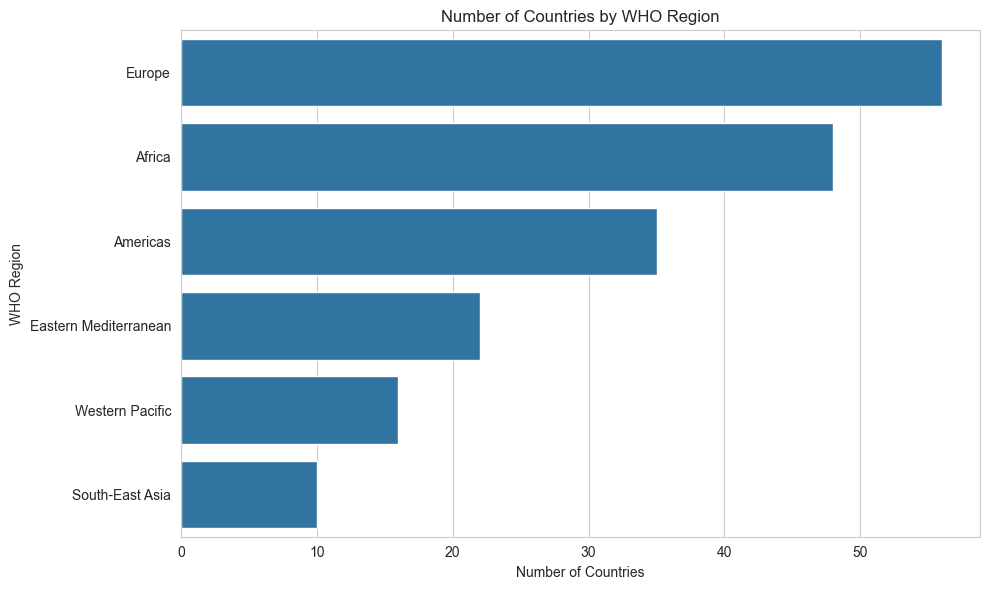

In [14]:
# Countries by WHO region
region_counts = df["WHO Region"].value_counts()

plt.figure(figsize=(10, 6))
sns.countplot(data=df, y="WHO Region", order=region_counts.index)
plt.title("Number of Countries by WHO Region")
plt.xlabel("Number of Countries")
plt.ylabel("WHO Region")
plt.tight_layout()
plt.show()

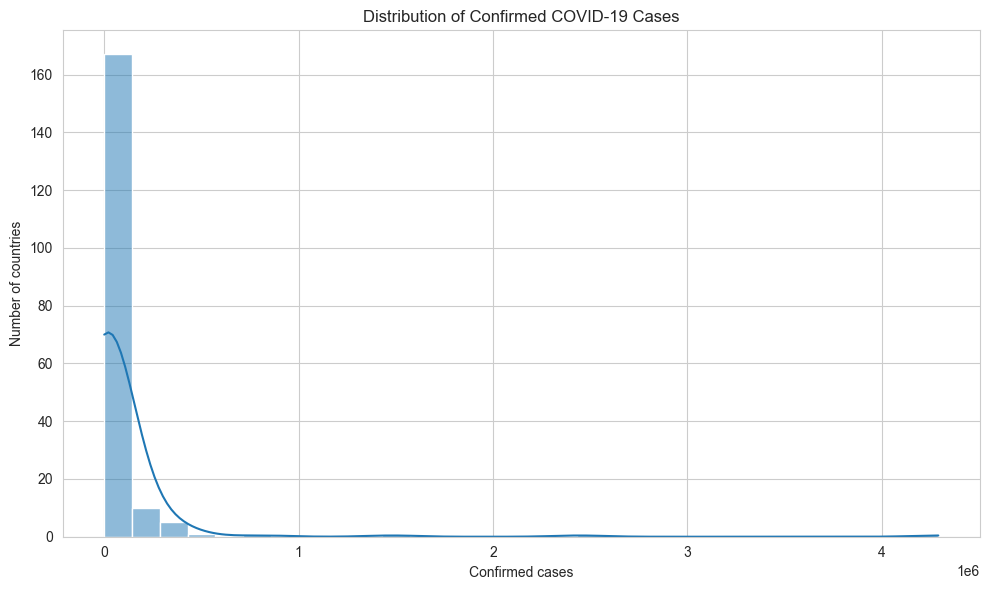

In [15]:
# Distribution of confirmed cases
plt.figure(figsize=(10, 6))
sns.histplot(df["Confirmed"].dropna(), bins=30, kde=True)
plt.title("Distribution of Confirmed COVID-19 Cases")
plt.xlabel("Confirmed cases")
plt.ylabel("Number of countries")
plt.tight_layout()
plt.show()

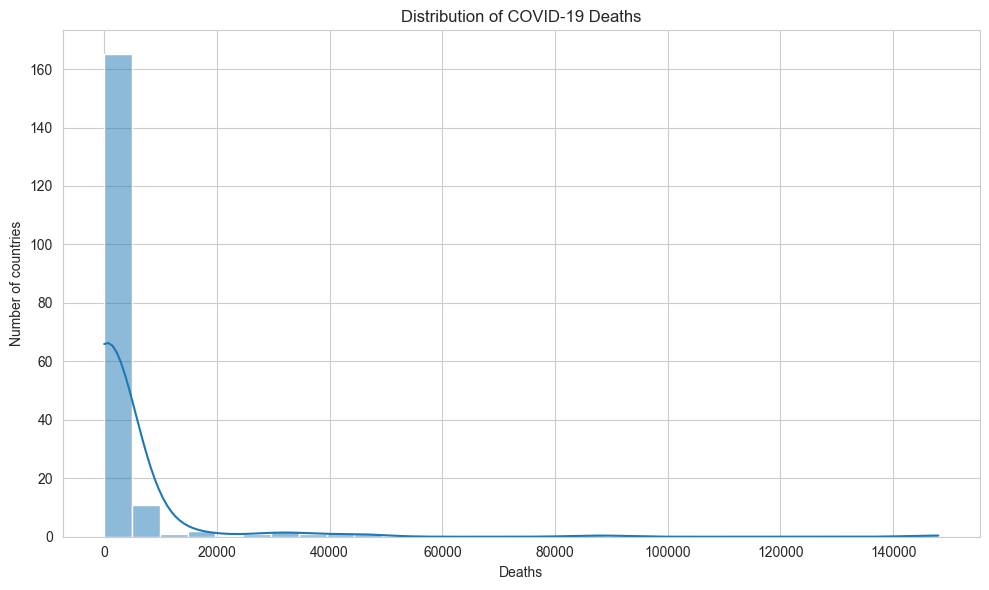

In [16]:
# Distribution of deaths
plt.figure(figsize=(10, 6))
sns.histplot(df["Deaths"].dropna(), bins=30, kde=True)
plt.title("Distribution of COVID-19 Deaths")
plt.xlabel("Deaths")
plt.ylabel("Number of countries")
plt.tight_layout()
plt.show()

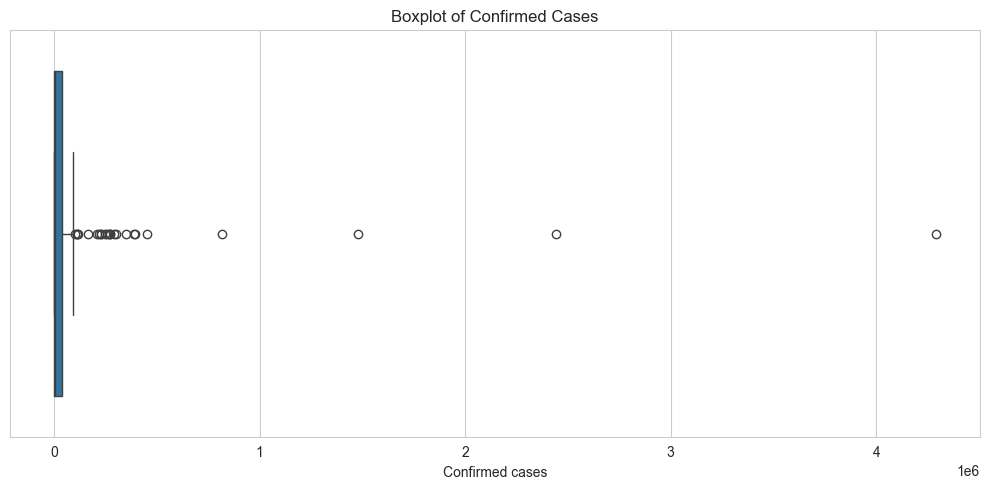

In [17]:
# Boxplots help show skew and outliers
plt.figure(figsize=(10, 5))
sns.boxplot(x=df["Confirmed"])
plt.title("Boxplot of Confirmed Cases")
plt.xlabel("Confirmed cases")
plt.tight_layout()
plt.show()

In [ ]:
# New cases by country: top 10
top_new_cases = df.nlargest(10, "New cases").sort_values("New cases")

plt.figure(figsize=(10, 6))
sns.barplot(data=top_new_cases, x="New cases", y="Country/Region")
plt.title("Top 10 Countries by New Cases")
plt.xlabel("New cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 8. Top-country comparisons

In [ ]:
# Top 10 countries by confirmed cases
top_confirmed = df.nlargest(10, "Confirmed").sort_values("Confirmed", ascending=True)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_confirmed, x="Confirmed", y="Country/Region")
plt.title("Top 10 Countries by Confirmed Cases")
plt.xlabel("Confirmed cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:
# Top 10 countries by deaths
top_deaths = df.nlargest(10, "Deaths").sort_values("Deaths", ascending=True)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_deaths, x="Deaths", y="Country/Region")
plt.title("Top 10 Countries by Deaths")
plt.xlabel("Deaths")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:
# Top 10 countries by recovered cases
top_recovered = df.nlargest(10, "Recovered").sort_values("Recovered", ascending=True)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_recovered, x="Recovered", y="Country/Region")
plt.title("Top 10 Countries by Recovered Cases")
plt.xlabel("Recovered cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:
# Top 10 countries by active cases
top_active = df.nlargest(10, "Active").sort_values("Active", ascending=True)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_active, x="Active", y="Country/Region")
plt.title("Top 10 Countries by Active Cases")
plt.xlabel("Active cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 9. Case outcomes and percentage metrics

In [ ]:
# Display countries with highest reported death percentage
top_death_rate = df.nlargest(10, "Deaths / 100 Cases").sort_values("Deaths / 100 Cases")

plt.figure(figsize=(11, 7))
sns.barplot(data=top_death_rate, x="Deaths / 100 Cases", y="Country/Region")
plt.title("Top 10 Countries by Deaths per 100 Confirmed Cases")
plt.xlabel("Deaths / 100 cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [ ]:
# Display countries with highest reported recovery percentage
top_recovery_rate = df.nlargest(10, "Recovered / 100 Cases").sort_values("Recovered / 100 Cases")

plt.figure(figsize=(11, 7))
sns.barplot(data=top_recovery_rate, x="Recovered / 100 Cases", y="Country/Region")
plt.title("Top 10 Countries by Recoveries per 100 Confirmed Cases")
plt.xlabel("Recovered / 100 cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 10. Bivariate analysis
Compare two variables to look for patterns. Correlation does not prove causation.

In [ ]:
# Confirmed cases versus deaths
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Confirmed", y="Deaths", hue="WHO Region", alpha=0.8)
plt.title("Confirmed Cases vs Deaths by WHO Region")
plt.xlabel("Confirmed cases")
plt.ylabel("Deaths")
plt.tight_layout()
plt.show()

In [ ]:
# Confirmed cases versus recovered cases
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Confirmed", y="Recovered", hue="WHO Region", alpha=0.8)
plt.title("Confirmed Cases vs Recovered Cases by WHO Region")
plt.xlabel("Confirmed cases")
plt.ylabel("Recovered cases")
plt.tight_layout()
plt.show()

In [ ]:
# Weekly increase versus new cases
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="1 week change", y="New cases", hue="WHO Region", alpha=0.8)
plt.title("One-Week Change vs New Cases")
plt.xlabel("One-week change in confirmed cases")
plt.ylabel("New cases")
plt.tight_layout()
plt.show()

In [ ]:
# WHO region comparison of confirmed cases
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="WHO Region", y="Confirmed")
plt.title("Confirmed Cases by WHO Region")
plt.xlabel("WHO Region")
plt.ylabel("Confirmed cases")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 11. Multivariate analysis

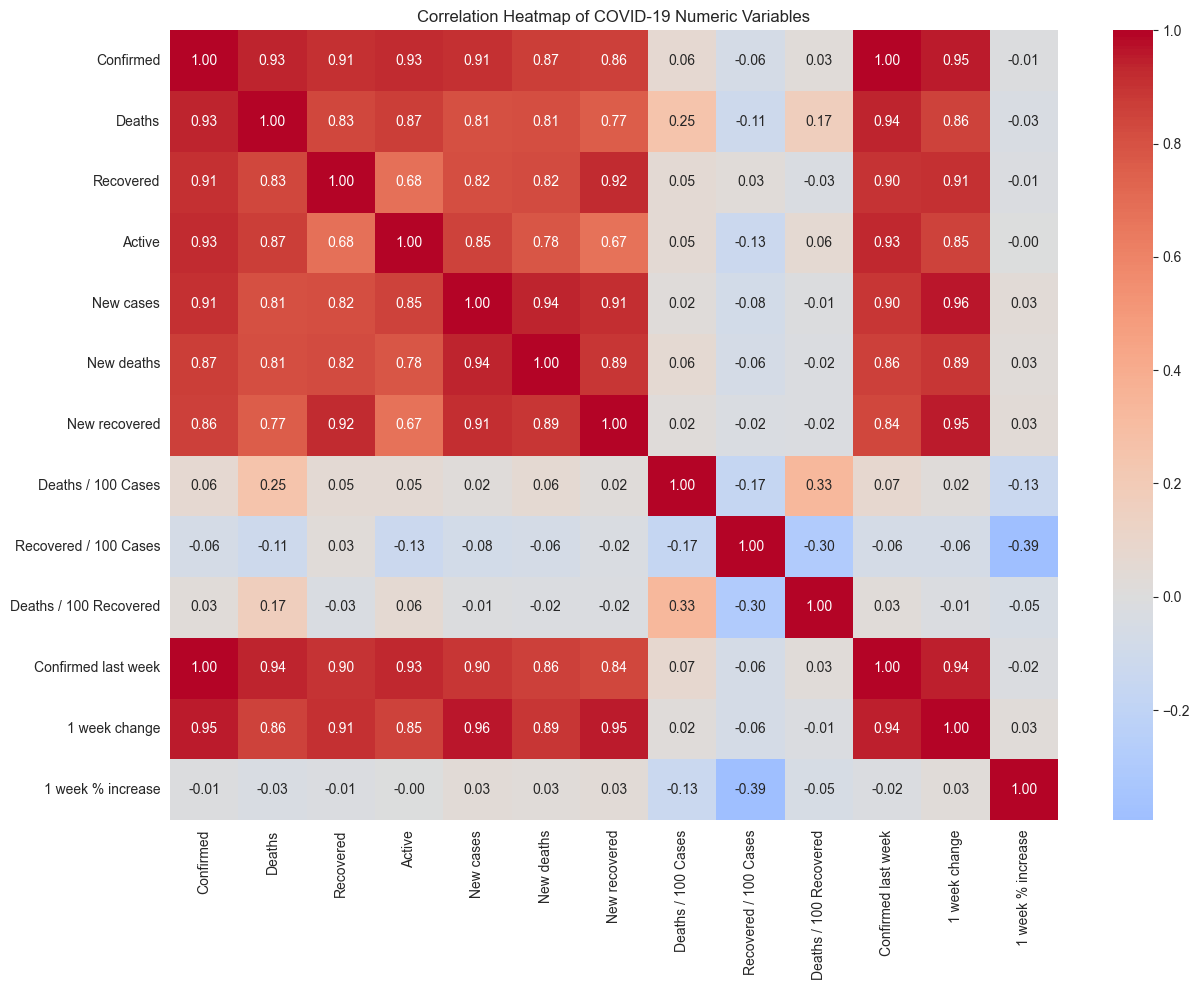

In [18]:
# Correlation matrix for numeric variables
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of COVID-19 Numeric Variables")
plt.tight_layout()
plt.show()

In [ ]:
# Compare confirmed cases, deaths, recovered and active cases for the top 10 countries
top_10 = df.nlargest(10, "Confirmed")
comparison_columns = ["Country/Region", "Confirmed", "Deaths", "Recovered", "Active"]
top_10_comparison = top_10[comparison_columns].set_index("Country/Region")

top_10_comparison.plot(kind="bar", figsize=(14, 7))
plt.title("COVID-19 Case Comparison for Top 10 Countries")
plt.xlabel("Country")
plt.ylabel("Reported count")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

## 12. WHO region summary

In [19]:
region_summary = df.groupby("WHO Region", observed=False)[
    ["Confirmed", "Deaths", "Recovered", "Active", "New cases", "New deaths"]
].sum().sort_values("Confirmed", ascending=False)

display(region_summary)

,Confirmed,Deaths,Recovered,Active,New cases,New deaths
WHO Region,,,,,,
Americas,8839286,342732,4468616,4027938,129531,3555
Europe,3299523,211144,1993723,1094656,22294,304
South-East Asia,1835297,41349,1156933,637015,48993,734
Eastern Mediterranean,1490744,38339,1201400,251005,12410,445
Africa,723207,12223,440645,270339,12176,353
Western Pacific,292428,8249,206770,77409,3289,24


In [ ]:
region_summary[["Confirmed", "Deaths", "Recovered", "Active"]].plot(
    kind="bar", figsize=(13, 7)
)
plt.title("COVID-19 Counts by WHO Region")
plt.xlabel("WHO Region")
plt.ylabel("Reported count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 13. Quick findings from the dataset
The cells below calculate the values from the CSV rather than hard-coding results.

In [20]:
print("=" * 70)
print("KEY DATASET FINDINGS")
print("=" * 70)
print("Countries/regions represented:", df["Country/Region"].nunique())
print("WHO regions represented:", df["WHO Region"].nunique())
print("Total confirmed cases in this dataset:", f'{df["Confirmed"].sum():,}')
print("Total reported deaths in this dataset:", f'{df["Deaths"].sum():,}')
print("Total reported recovered cases in this dataset:", f'{df["Recovered"].sum():,}')
print("Total active cases in this dataset:", f'{df["Active"].sum():,}')

highest_confirmed = df.loc[df["Confirmed"].idxmax(), ["Country/Region", "Confirmed"]]
highest_deaths = df.loc[df["Deaths"].idxmax(), ["Country/Region", "Deaths"]]
highest_new_cases = df.loc[df["New cases"].idxmax(), ["Country/Region", "New cases"]]

print("\nCountry with the highest confirmed cases:")
print(highest_confirmed.to_string())
print("\nCountry with the highest reported deaths:")
print(highest_deaths.to_string())
print("\nCountry with the highest new cases:")
print(highest_new_cases.to_string())

KEY DATASET FINDINGS
Countries/regions represented: 187
WHO regions represented: 6
Total confirmed cases in this dataset: 16,480,485
Total reported deaths in this dataset: 654,036
Total reported recovered cases in this dataset: 9,468,087
Total active cases in this dataset: 6,358,362

Country with the highest confirmed cases:
Country/Region         US
Confirmed         4290259

Country with the highest reported deaths:
Country/Region        US
Deaths            148011

Country with the highest new cases:
Country/Region       US
New cases         56336


## 14. Conclusion

This EDA project inspected the COVID-19 country-level dataset, checked data quality, summarized numerical variables, compared countries and WHO regions, and visualized relationships among confirmed cases, deaths, recoveries, active cases, and weekly changes.

When interpreting the charts:
- Total counts are influenced by country population and reporting practices.
- Percentage metrics can be unstable for countries with relatively few cases.
- Correlation indicates association, not causation.
- The dataset is a historical snapshot, not current medical or public-health guidance.

**Project completed.**